# Pipeline, Model Fairness Explainbility & Deploy the Best Prediction Model

Based on the model comparison conducted in the **Bagging_Boosting_Model_2** analysis, the standard **XGBoost Regressor** showed the strongest overall performance for predicting a single property sale price. Therefore, this model was selected as the final model for pipeline development and **Streamlit** deployment.

**Streamlit** was used to deploy the final model as an interactive web application. Users can enter property, location, and market information through the interface, and the saved pipeline automatically preprocesses the inputs and produces an estimated sale price. The application was deployed through Streamlit Community Cloud using the model and application files stored in the GitHub repository.

We will use the same '**cleaned_data_eda.csv**' dataset and the same predictor features used in the previous **Bagging_Boosting_Model_2** analysis to maintain consistency between model training, evaluation, and deployment.

The previously selected XGBoost hyperparameters will be reused rather than performing hyperparameter tuning again. A pipeline will be constructed to combine the required data preprocessing steps with the final XGBoost model, allowing new property information to be processed and passed directly into the trained model for sale-price prediction.

# Imports

In [2]:
# basic setup
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# shap tool for explainable model
import shap

# train, test, validation sets
from sklearn.model_selection import (
    train_test_split,
    GridSearchCV
)

# pre-processing 
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer, make_column_transformer 
from sklearn.pipeline import Pipeline

# boosting model
from xgboost import XGBRegressor

# metrics score
from sklearn.metrics import (
    root_mean_squared_error,
    mean_absolute_error,
    r2_score,
    mean_absolute_percentage_error
)

c:\Users\junki\AppData\Local\Programs\Python\Python314\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
from sklearn import set_config

# display models and pipeline as plain text instead of HTML diagram
set_config(display="text")

# Data

Let's call back out **cleaned_data_eda.csv** dataset

In [4]:
# call csv dataset
df=pd.read_csv('cleaned_data_eda.csv')
print(df.shape)
df.head()

(47549, 31)


,ViewYN,PoolPrivateYN,ClosePrice,Latitude,Longitude,LivingArea,CountyOrParish,AttachedGarageYN,ParkingTotal,BathroomsTotalInteger,...,CPI,Age,LotDensity,FlooringType,SchoolDistrict,AgeGroup,CountyOrParish2,FlooringType2,SchoolCount2Miles,SchoolCountGroup
0,1,0,890000.0,34.180411,-118.342020,1434.0,Los Angeles,0,1,1.0,...,315.605,86.0,4.513947,Unknown,Burbank Unified,70+,Los Angeles,Unknown,21.0,20+ Schools
1,0,0,1138000.0,32.574359,-117.023836,2872.0,San Diego,1,6,3.0,...,315.605,25.0,1.817201,Unknown,Unknown,21-40,San Diego,Unknown,12.0,11-20 Schools
2,1,0,681877.0,33.725080,-117.222302,2824.0,Riverside,1,2,3.0,...,315.605,2.0,2.478754,Unknown,Unknown,0-5,Riverside,Unknown,2.0,1-5 Schools
3,1,0,900000.0,34.203479,-118.643567,2500.0,Los Angeles,1,2,3.0,...,315.605,55.0,3.334400,Unknown,Los Angeles Unified,41-70,Los Angeles,Unknown,12.0,11-20 Schools
4,0,0,862000.0,34.460368,-118.490755,2363.0,Los Angeles,1,2,3.0,...,315.605,31.0,4.953449,Unknown,Unknown,21-40,Los Angeles,Unknown,4.0,1-5 Schools


Let's check the data types and missing values in each feature.

In [5]:
df.dtypes

ViewYN                     int64
PoolPrivateYN              int64
ClosePrice               float64
Latitude                 float64
Longitude                float64
LivingArea               float64
CountyOrParish               str
AttachedGarageYN           int64
ParkingTotal               int64
BathroomsTotalInteger    float64
City                         str
BedroomsTotal            float64
FireplaceYN                int64
Stories                  float64
NewConstructionYN          int64
GarageSpaces             float64
LotSizeSquareFeet        float64
SalesTaxRate             float64
UnemploymentRate         float64
MortgageRate30Fixed      float64
FedInterestRate          float64
CPI                      float64
Age                      float64
LotDensity               float64
FlooringType                 str
SchoolDistrict               str
AgeGroup                     str
CountyOrParish2              str
FlooringType2                str
SchoolCount2Miles        float64
SchoolCoun

In [6]:
df.isna().sum()

ViewYN                   0
PoolPrivateYN            0
ClosePrice               0
Latitude                 0
Longitude                0
LivingArea               0
CountyOrParish           0
AttachedGarageYN         0
ParkingTotal             0
BathroomsTotalInteger    0
City                     0
BedroomsTotal            0
FireplaceYN              0
Stories                  0
NewConstructionYN        0
GarageSpaces             0
LotSizeSquareFeet        0
SalesTaxRate             0
UnemploymentRate         0
MortgageRate30Fixed      0
FedInterestRate          0
CPI                      0
Age                      0
LotDensity               0
FlooringType             0
SchoolDistrict           0
AgeGroup                 0
CountyOrParish2          0
FlooringType2            0
SchoolCount2Miles        0
SchoolCountGroup         0
dtype: int64

There is no missing values. We identified there is no implicit missing values as well that this dataset is cleaned from previous files. Now let's transform the categorical features with hot en-coding for computer to read categorical values. We will not use standard scaler at this point due to tree of boosting model of XGBoost Regressor that it does not requires standard scaler. 

In [7]:
continuous= [
    "Age",
    "CPI",
    "FedInterestRate",
    "Latitude",
    "LivingArea",
    "Longitude",
    "LotDensity",
    "LotSizeSquareFeet",
    "MortgageRate30Fixed",
    "SalesTaxRate",
    "UnemploymentRate"
]

discrete= [
    "BathroomsTotalInteger",
    "BedroomsTotal",
    "Stories",
    "GarageSpaces",
    "ParkingTotal",
    "SchoolCount2Miles"
]

categorical = [
    "CountyOrParish2",
    "FlooringType2",
    "AttachedGarageYN",
    "FireplaceYN",
    "NewConstructionYN",
    "PoolPrivateYN",
    "ViewYN"

]

# make feature pipeline
preprocessor = ColumnTransformer(
    transformers=[
        (
            "numerical",
            "passthrough",
            continuous + discrete
        ),
        (
            "categorical",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=True,
                drop="first"
            ),
            categorical
        )
    ]
)

Let's split the dataset for independent and dependent variables with spliting x and y training and test set.

In [8]:
# split features into independent and dependent variable
X = df.drop(columns = ["ClosePrice"])

y = df["ClosePrice"]

# construct training and test set
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=48)

# Model

We had observed the best model with best hyper parameters on XGBoost Regressor from Bagging_Boosting_Model_2 file. We will use exact same parameters method using the pipeline process.

In [9]:
# create final model of xgboost regressor
model_xgb = XGBRegressor(
    
    objective="reg:squarederror",
    tree_method="hist",

    max_depth=11,
    min_child_weight=10,
    gamma=0,

    subsample=1,
    colsample_bytree=0.6,

    reg_alpha=0,
    reg_lambda=5,

    n_estimators = 500,
    learning_rate = 0.04,

    random_state=48,
    n_jobs=1
)


pipeline_model = Pipeline(
    [
        ("preprocessor", preprocessor),
        ("model", model_xgb)
    ]
)

pipeline_model.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('numerical', 'passthrough',
                                                  ['Age', 'CPI',
                                                   'FedInterestRate',
                                                   'Latitude', 'LivingArea',
                                                   'Longitude', 'LotDensity',
                                                   'LotSizeSquareFeet',
                                                   'MortgageRate30Fixed',
                                                   'SalesTaxRate',
                                                   'UnemploymentRate',
                                                   'BathroomsTotalInteger',
                                                   'BedroomsTotal', 'Stories',
                                                   'GarageSpaces',
                                                   'ParkingTotal',
                          

Let's test the result of this model.

In [10]:
# predict close price from training and test set
pred_train2 = pipeline_model.predict(X_train)

pred_test2 = pipeline_model.predict(X_test)

# conduct median absolute percentage error
def median_absolute_percentage_error(y_true, y_pred):
    return np.median(np.abs((y_true - y_pred) / y_true))


# show the results of MAPE, MAE, RMSE, and R^2
print(f"MAPE: {mean_absolute_percentage_error(y_test, pred_test2) * 100} %")
print(f"MdAPE: {median_absolute_percentage_error(y_test, pred_test2) * 100} %")
print(f"RMSE: ${root_mean_squared_error(y_test, pred_test2)}")
print(f"MAE: ${mean_absolute_error(y_test, pred_test2)}")
print(f"R^2_test: {r2_score(y_test, pred_test2) * 100} %")
print(f"R^2_train: {r2_score(y_train, pred_train2) * 100} %")

MAPE: 11.611514031236894 %
MdAPE: 7.752534374222554 %
RMSE: $248277.23762744264
MAE: $130873.46535180074
R^2_test: 88.35522238868238 %
R^2_train: 98.01650745844546 %


- Test MAPE, predicted property prices differed from actual sale prices by approximately $11.61\%$ on average.

- Test MdAPE, the half of properties predicted sold price of the errors approximately $7.75\%$
 or less. This suggests that a typcial property was predicted within about $7.75\%$ of its actual sold price.

- Test MAE, predicted prices were off by approximately $\$130,873$ on average.

- Test RMSE is $\$248,277$ and it is higher than the MAE because it gives greater weight to large prediction errors. This difference suggests that some properties had large prediction errors.

- The model has test $R^2$, explaining approximately 88.57% of the variation in property prices amoong unseen observations.

- The gaps of $R^2$ between training $98\%$ and test $88\%$ is $10\%$ indicates small-mediate overfitting. However, the strong test performance suggests that final model still generalizes well to unseen properties.**

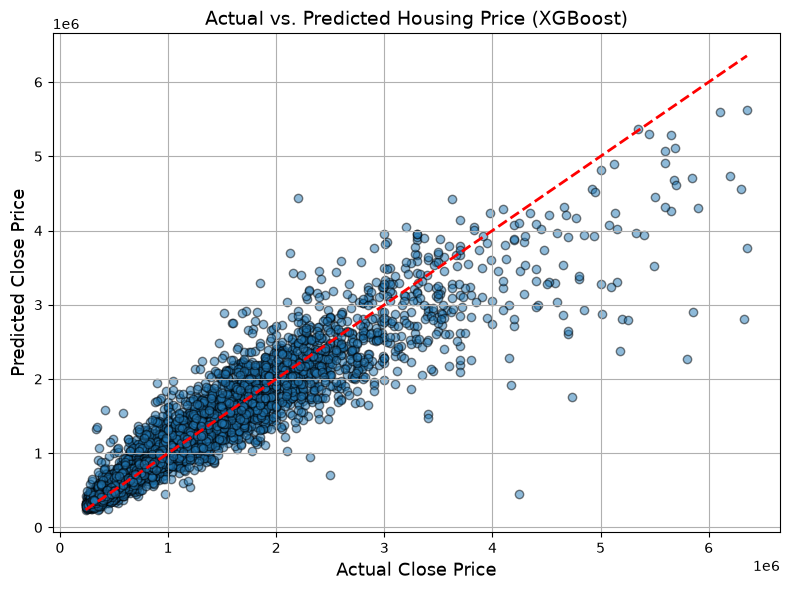

In [11]:
# show scatterplot for distribution actual vs. predicted price
plt.figure(figsize=(8, 6))
plt.scatter(y_test, pred_test2, alpha=0.5, edgecolor='k')

# show the ideal red line for prediction
min_price = min(y_test.min(), pred_test2.min())
max_price = max(y_test.max(), pred_test2.max())


plt.plot([min_price, max_price],
         [min_price, max_price],
         color='red', linestyle='--', linewidth=2)

plt.title("Actual vs. Predicted Housing Price (XGBoost)", fontsize=14)
plt.xlabel("Actual Close Price", fontsize=13)
plt.ylabel("Predicted Close Price", fontsize=13)
plt.grid(True)
plt.tight_layout()
plt.show()


The most predicted values are close to the diagonal reference line, suggesting generally strong predictive performance. The low to mid property prices below $4 million clustered around the red line.

Above $4 million, the more actual price increase, the prediction of price tends to underpredict prices at upper end market falling down from red line. Serveral large errors are showing why RMSE is higher than MAE.

# Model Fairness Explainability  

## 1. SHAP 

We need to call back the test data and model individually from the pipeline_model of previous pipeline, then it can calculate SHAP values from each feature.

In [12]:
# call out preprocessed steps
fitted_processor = pipeline_model.named_steps["preprocessor"]

# call out model from pipeline
xgb_model = pipeline_model.named_steps["model"]

In [13]:
# transform the test set using trained processor previously
x_test_transformed = fitted_processor.transform(X_test)

# create SHAP TreeExplainer
explainer = shap.TreeExplainer(xgb_model)

# calculate SHAP values
shap_values = explainer.shap_values(x_test_transformed)



### 1) SHAP Reconstruction Reliability

Let's identify if the SHAP reconstruction prediction of close prices across properties.

In [14]:
# Reconstruct model prediction using SHAP
shap_prediction = explainer.expected_value.item() + shap_values.sum(axis = 1)

# Original XGBoost prediction
xgb_prediction = xgb_model.predict(x_test_transformed)

# Difference
errors = abs(shap_prediction - xgb_prediction)

print(f"Mean Reconstruction Error: ${errors.mean():,.2f}")
print(f"Max Reconstruction Error:  ${errors.max():,.2f}")

Mean Reconstruction Error: $0.49
Max Reconstruction Error:  $10.50


There is less error of reconstruction SHAP model and original model of XGBoost mean is $\$0.49$ and maximum error is $\$10.50$. This is pretty good fit to investigate.

### 2) Feature Correlation

We will check the features multicollinearity might show overlapping information and improve interpretation on SHAP reliability. We use both **Person** and **Spearman** correlation check to see if they have linear or/and monotonic relationship among features. We need this because the multicollinearity affect

- Shared information that pair features show related aspects

- There are feature attribution that model might rely more on one feature that has highest correlation from its pair

- There might cause limitation on interpretation feature contribution in the model

In [15]:
# show Pearson correlation chart
df_corr = df[continuous + discrete].corr()

display(df_corr)

,Age,CPI,FedInterestRate,Latitude,LivingArea,Longitude,LotDensity,LotSizeSquareFeet,MortgageRate30Fixed,SalesTaxRate,UnemploymentRate,BathroomsTotalInteger,BedroomsTotal,Stories,GarageSpaces,ParkingTotal,SchoolCount2Miles
Age,1.000000,-0.004235,0.006027,0.043284,-0.427564,-0.177726,0.012845,-0.072658,0.009167,0.334532,-0.006354,-0.432708,-0.286129,-0.326592,-0.443536,-0.078940,0.545764
CPI,-0.004235,1.000000,-0.813616,0.009641,0.013802,-0.013941,-0.000593,0.003848,-0.060543,0.002734,0.727245,0.010778,0.000032,-0.000382,0.009235,0.010203,-0.007164
FedInterestRate,0.006027,-0.813616,1.000000,0.002193,-0.008325,-0.001507,-0.000951,-0.003859,-0.267152,0.005368,-0.276237,-0.009348,-0.000214,0.006739,-0.011729,-0.007621,0.007768
Latitude,0.043284,0.009641,0.002193,1.000000,-0.063146,-0.917190,0.040168,0.026403,-0.012164,0.236286,0.017767,-0.082877,-0.046023,-0.025555,-0.096825,-0.073187,-0.016654
LivingArea,-0.427564,0.013802,-0.008325,-0.063146,1.000000,0.065356,-0.073561,0.156369,-0.009014,-0.130843,0.015530,0.818174,0.653928,0.496205,0.482990,0.115821,-0.300438
Longitude,-0.177726,-0.013941,-0.001507,-0.917190,0.065356,1.000000,0.025400,0.032736,0.014826,-0.297056,-0.023427,0.078153,0.029322,-0.007917,0.119275,0.081282,-0.115353
LotDensity,0.012845,-0.000593,-0.000951,0.040168,-0.073561,0.025400,1.000000,0.905282,0.005320,-0.088306,-0.003988,-0.096132,-0.112455,-0.143524,-0.056462,0.090372,-0.160824
LotSizeSquareFeet,-0.072658,0.003848,-0.003859,0.026403,0.156369,0.032736,0.905282,1.000000,0.004041,-0.110412,0.000105,0.085926,0.033757,-0.062083,0.074396,0.109797,-0.220368
MortgageRate30Fixed,0.009167,-0.060543,-0.267152,-0.012164,-0.009014,0.014826,0.005320,0.004041,1.000000,-0.006729,-0.689392,-0.009001,0.000559,-0.008707,-0.001481,0.002554,0.002237
SalesTaxRate,0.334532,0.002734,0.005368,0.236286,-0.130843,-0.297056,-0.088306,-0.110412,-0.006729,1.000000,0.009030,-0.138834,-0.066341,-0.109810,-0.128762,-0.080320,0.372791


In [16]:
# Extract upper triangle to avoid duplicate pairs
pearson_pairs = df[continuous + discrete].corr(method="pearson").stack()
spearman_pairs = df[continuous + discrete].corr(method="spearman").stack()

# Combine both methods
corr_comparison = pd.DataFrame({
    "Pearson": pearson_pairs,
    "Spearman": spearman_pairs
})

# Keep pairs that meet threshold in EITHER method
corr_comparison = corr_comparison[
    (
        (corr_comparison["Pearson"].abs() >= 0.7) &
        (corr_comparison["Pearson"].abs() < 1)
    ) |
    (
        (corr_comparison["Spearman"].abs() >= 0.7) &
        (corr_comparison["Spearman"].abs() < 1)
    )
]

# Compare absolute correlation strength
corr_comparison["Difference"] = (
    corr_comparison["Spearman"].abs() -
    corr_comparison["Pearson"].abs()
)

corr_comparison["Max_Abs_Corr"] = corr_comparison[
    ["Pearson", "Spearman"]
].abs().max(axis=1)

corr_comparison = corr_comparison.sort_values(
    "Max_Abs_Corr",
    ascending=False
)

display(corr_comparison.round(3))

,,Pearson,Spearman,Difference,Max_Abs_Corr
Longitude,Latitude,-0.917,-0.744,-0.173,0.917
Latitude,Longitude,-0.917,-0.744,-0.173,0.917
LotSizeSquareFeet,LotDensity,0.905,0.673,-0.233,0.905
LotDensity,LotSizeSquareFeet,0.905,0.673,-0.233,0.905
UnemploymentRate,CPI,0.727,0.837,0.110,0.837
CPI,UnemploymentRate,0.727,0.837,0.110,0.837
BathroomsTotalInteger,LivingArea,0.818,0.799,-0.019,0.818
LivingArea,BathroomsTotalInteger,0.818,0.799,-0.019,0.818
CPI,FedInterestRate,-0.814,-0.657,-0.157,0.814
FedInterestRate,CPI,-0.814,-0.657,-0.157,0.814



- Longitude and Latitude have Pearson of -0.917 and Spearman -0.744 which is strong negative linear association than monotonic relationship. They are presenting overlap geographic information. We should interpret them together than as independent causes of property prices.

- Living Area and Bathroom have Pearson of 0.818 and Spearman 0.799 which is strong positvie linear and rank based association. They are sharing property spacial attributes.

- The Lot Density and Lot Size have strong linear relationship that contains redundant information

- CPI and Unemployment Rate shows stronger positive monotonic relationship than linear that containing macro economic features are overlapping information.

- **Individual of feature that faced multicollinearity should be interpreted cautiously that the model may distribute predictive importance across correlated features.** 

Let's check the baseline of SHAP represents the model's reference output for explainer of both Global and Local.

In [17]:
# measure the baseline of SHAP value
explainer.expected_value

np.float32(1.0415912e+06)

The baseline is $\$1,041,591$ that SHAP will measure the global and local prediction starting from $\$1,041,591$ close price. 

### 1) Global Explaination

Let's show the feature importance and direction answering how features influence on predicted property prices. 

Let's show the **Beeswarm** and **Bar** plots for global explaination. The SHAP of **Bar** plot shows how important each features in the model overall, and **Beeswarm** plot shows direction and magnitude of feature contributions to the

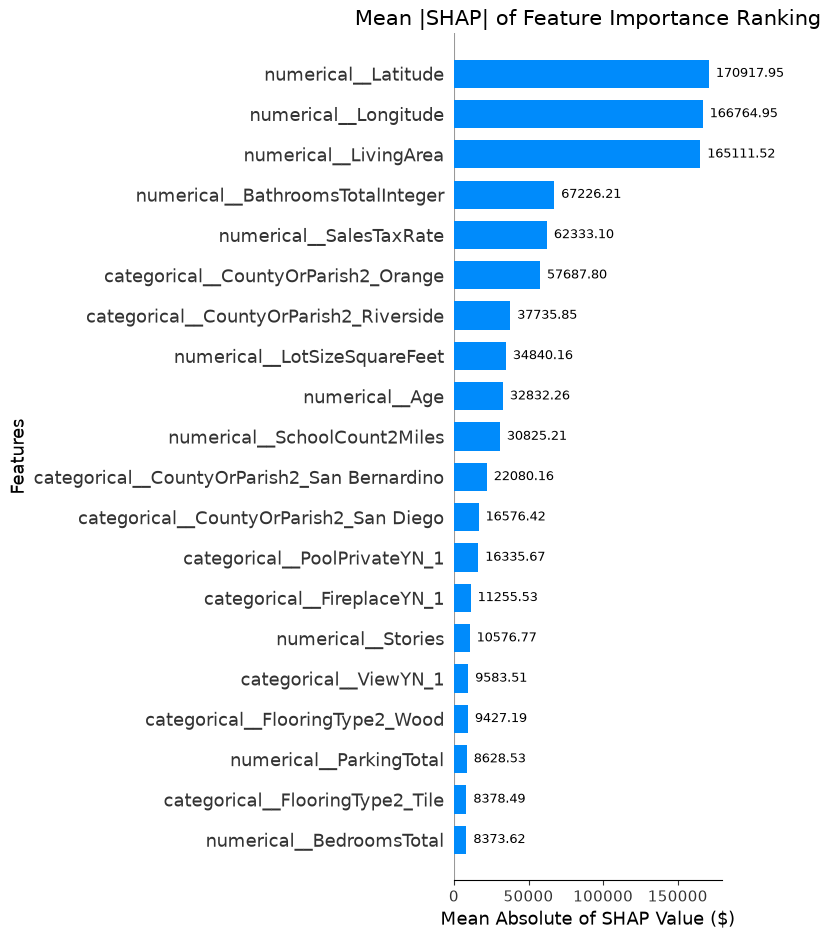

In [18]:
# show SHAP bar plot
plt.figure(figsize=(6, 4))
shap.summary_plot(
    shap_values, 
    x_test_transformed, 
    feature_names= fitted_processor.get_feature_names_out(),
    plot_type="bar",
    show=False
)

# add values to the right of each bar
ax = plt.gca()

for container in ax.containers:
    ax.bar_label(
        container,
        fmt = "%.2f",
        padding = 5,
        fontsize = 9
    )

# costumize plot
plt.title("Mean |SHAP| of Feature Importance Ranking", fontsize=15)
plt.xlabel("Mean Absolute of SHAP Value ($)", fontsize = 13)
plt.ylabel("Features", fontsize = 13)
plt.tight_layout()
plt.show()

Regardless of increase or decrease contribution to prediction, 

- The Latitude, Longitude, and Living Area were the greatest contribution on predicting property close prices, and it changes predicted prices by approximately $\$165,000$ ~ $\$171,000$ on average. 

- **The geographic location, living area, and tax sales are major influenced of model prediction**.

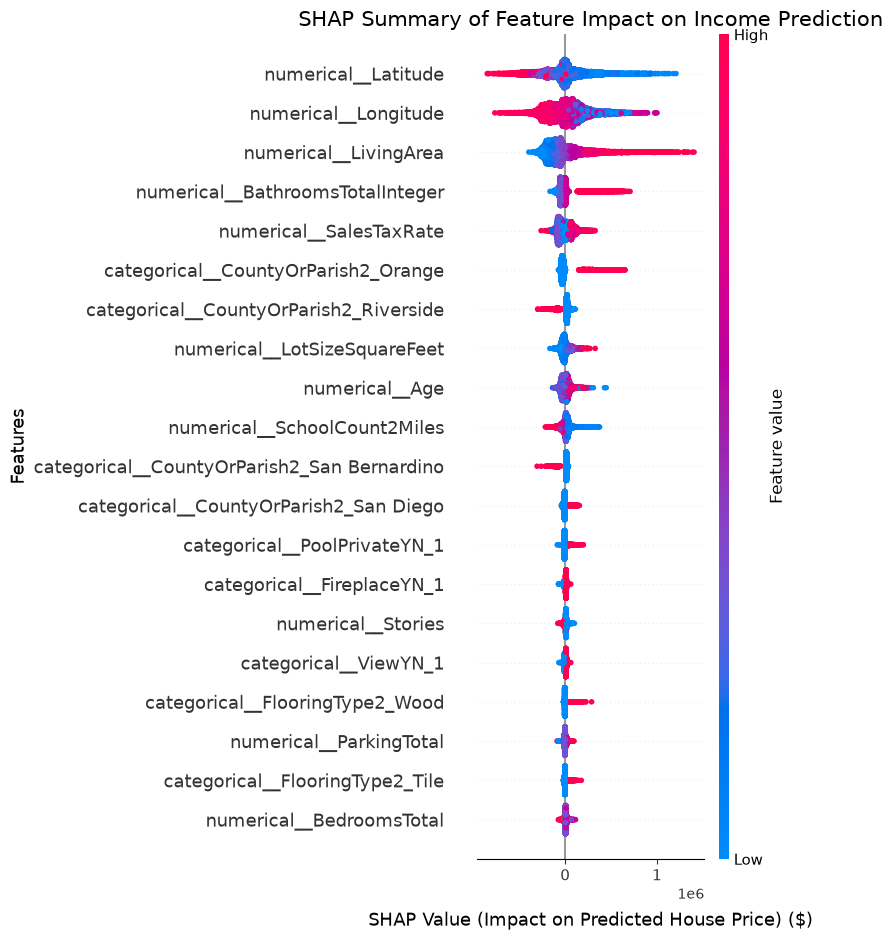

In [19]:
# show Beeswarm plot 
shap.summary_plot(
    shap_values, 
    x_test_transformed, 
    feature_names=fitted_processor.get_feature_names_out(),
      show=False
)

plt.title("SHAP Summary of Feature Impact on Income Prediction", fontsize=15)

# adjust x-axis label
plt.xlabel(
    "SHAP Value (Impact on Predicted House Price) ($)",
    fontsize = 13,
    labelpad = 20
)

plt.ylabel("Features", fontsize = 13)
plt.tight_layout()
plt.show()

The dot color of blue presents low value of that property aligned with feature, and red presents high value.

- The properties with lower latitude generally receive higher predicted close prices, while properties with higher latitude receive lower predicted close price. Longitude influences predicted close prices, but its relationship appears more complex than simple increasing or decreasing patterns. **This might suggest that the model captures regional differences in California's property market, particularly between northern and southern locations and potentially between coastal and inland areas. They are sharing geographic information, and individual SHAP contribution should not be interpreted as independent effects on close price.**

- The living area was the third most influencial feature that higher area size tends to predict higher close prices. Then, the number of bathrooms come next to influencial feature that sharing property spacial information with living area as we saw from multicollinearity. **This might suggest that living area may already capture some predictive information associated with bathroom and bedrooms.**

- Sale tax rate shows fifth most influencial feature that higher sales tax are mostly concentrated zero to positive SHAP values, and lower sales tax rates are concentrated around zero to negative. Overall, sale tax rate influences model predictions, but the direction is less consistent than location and spacial features. Sale tax distribution is similar with longitude that this might suggest sale tax might capture some geographic or socioeconomic differences among California property markets. (We need more investigation)




### 2) Local Explaination

Let's use the SHAP of Local explaination identifying why does model made specific prediction for specific property. We will observe the properties where highest and lowest predicted close prices.

In [20]:
# call index for each highest and lowest close price predicted property
pred_high = np.argmax(pred_test2)
pred_low = np.argmin(pred_test2)

Let's first explore the property predicted highest close price.

In [21]:
# display the property predicted highest close price
display(X_test.iloc[pred_high].to_frame())

# show me predicted and actual close price
print(f"Predicted close price for #{pred_high} property: ${pred_test2[pred_high]}")
print(f"Actual close price for #{pred_high} property: ${y_test.iloc[pred_high]}")

,28857
ViewYN,1
PoolPrivateYN,1
Latitude,33.59838
Longitude,-117.814388
LivingArea,4258.0
CountyOrParish,Orange
AttachedGarageYN,1
ParkingTotal,6
BathroomsTotalInteger,5.0
City,Newport Coast


Predicted close price for #7219 property: $5620307.0
Actual close price for #7219 property: $6353250.0


The predicted price was $\$5,620,307$ and the actual close price was $\$6,353,250$. There  Let's see how the model decided on that prediction using **Waterfall** plot.

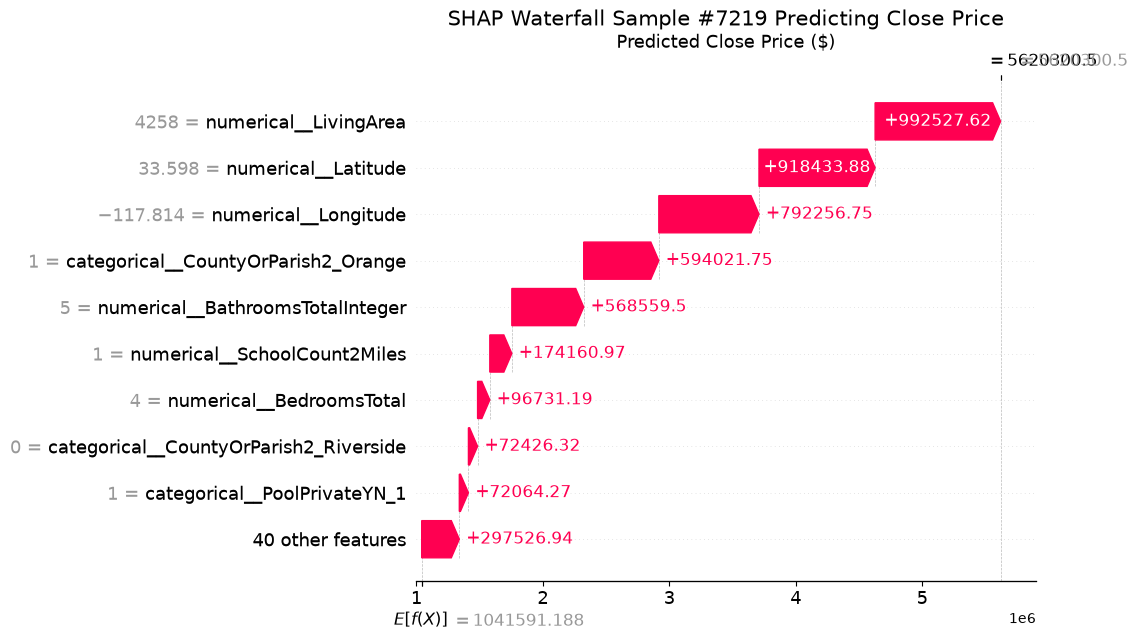

In [22]:
# generate SHAP local of one specific property
shap_high_pred = shap.Explanation(
    values = shap_values[pred_high],
    base_values = explainer.expected_value,
    data = x_test_transformed[pred_high],
    feature_names = fitted_processor.get_feature_names_out()
)

# generate SHAP waterfall plot
shap.plots.waterfall(shap_high_pred, show = False)
plt.title(f"SHAP Waterfall Sample #{pred_high} Predicting Close Price", fontsize = 15)
plt.xlabel("Predicted Close Price ($)", fontsize = 13)
plt.show()

The highest predited close price was the property of #7219 where started from the baseline of 1,041,591 came to predicted $\$5,620,300$.

In [23]:
# display property infromation predicted lowest close price
display(X_test.iloc[pred_low].to_frame(name = "Value"))

# show actual and predicted price of that property
print(f"Predicted close price for #{pred_low} property: ${pred_test2[pred_low]}")
print(f"Actual close price for #{pred_low} property: ${y_test.iloc[pred_low]}")

,Value
ViewYN,1
PoolPrivateYN,0
Latitude,37.306513
Longitude,-120.486369
LivingArea,1641.0
CountyOrParish,Merced
AttachedGarageYN,0
ParkingTotal,0
BathroomsTotalInteger,1.0
City,Merced


Predicted close price for #6679 property: $237840.25
Actual close price for #6679 property: $350000.0


The property #6679 predicted $\$237,840$ and the actual close price was $\$350,000$. Let's check why did the model predicted that close price.

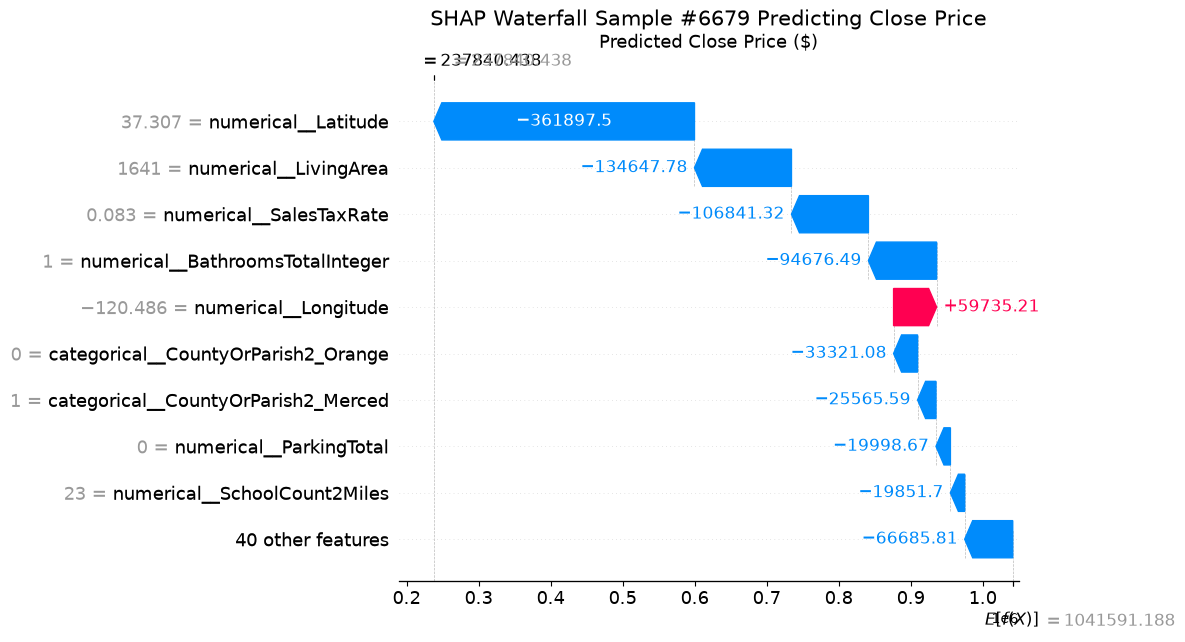

In [24]:
# s
shap_low_pred = shap.Explanation(
    values = shap_values[pred_low],
    base_values = explainer.expected_value,
    data = x_test_transformed[pred_low],
    feature_names = fitted_processor.get_feature_names_out()
)

# generate SHAP waterfall plot
shap.plots.waterfall(shap_low_pred, show = False)
plt.title(f"SHAP Waterfall Sample #{pred_low} Predicting Close Price", fontsize = 15)
plt.xlabel("Predicted Close Price ($)", fontsize = 13)
plt.show()

## 2. Fairness Analysis

We identified that model tends to rely on locational features on its prediction close price from SHAP analysis. It is good to check the fairness on model's prediction under locational features leveraging county feature measuring prediction performance on Mean Absolute Error (MAE), Mean Absolute Percentage Error (MAPE), and Mean Error. 

- Mean Absolute Error: Difference of prediction and actual close price

- Mean Absolute Percentage Error: Difference of prediction and actual clsoe price in percentage

- Mean Error: Direction of error on prediction performance.

The research question would be:

- **Does prediction performance differ geographically in California of residential housing market?** 

We will call back all the test datasets of independent and dependent features for analyze model prediction performance in terms of fairness. We choose test dataset for more reliable analysis on unseen data. 

In [25]:
# make a copy of test data 
df_fairness = X_test.copy()

# add informaiton of predication and actual close price performance
df_fairness["actual_price"] = y_test

df_fairness["predicted_price"] = pred_test2

df_fairness["error"] = df_fairness["actual_price"] - df_fairness["predicted_price"]

df_fairness["abs_error"] = df_fairness["error"].abs()

df_fairness["APE"] = (df_fairness["abs_error"] / df_fairness["actual_price"]) * 100

In [26]:
# group by county measuring mean/median errors
county_performance = (
    df_fairness
    .groupby("CountyOrParish2")
    .agg(
        N=("actual_price", "size"),
        MAE=("abs_error", "mean"),
        MAPE=("APE", "mean"),
        MeanError=("error", "mean"),
        MedianError = ("error", "median"),
        MedianActualPrice=("actual_price", "median")
    )
    .query("N >= 100")
    .sort_values("MAPE", ascending=False)
)

display(county_performance)

,N,MAE,MAPE,MeanError,MedianError,MedianActualPrice
CountyOrParish2,,,,,,
Others,110,178511.877699,24.506619,-210.507528,-27725.468750,499000.0
San Luis Obispo,166,161569.615964,14.531789,-1277.838102,-23074.656250,916500.0
Alameda,449,177360.775195,14.147566,20855.060830,8996.437500,1300000.0
Butte,126,67361.657778,13.986975,-14425.406706,-4569.765625,450250.0
Kern,121,52806.614540,12.925810,-19946.355759,-9100.906250,395000.0
San Diego,989,165373.312816,12.175318,-232.504613,-5753.875000,1056000.0
Los Angeles,2359,147219.244993,11.541047,10143.152925,1807.750000,945000.0
Contra Costa,451,125731.702952,11.385012,-16636.577536,-8843.875000,852000.0
Ventura,376,145612.199136,11.273896,-6429.014628,-13723.000000,965000.0


- The Others has higher relative prediction error of $24.51\%$ mean absolute error (MAPE). This group only contains 110 observation that combined geographcially diverse properties that were observed less properties sold in California. This suggest that it is difficult to generalize the heterogeneous areas.

- The **Almeda** and **San Luis** have relatively high MAPE and **Riverside** and **San Bernardino** counties tends to have predicted lowest MAPE. 

- There is no sufficient evidence to conclude that model discriminates against a particular county, and there is no specific pattern of direction mean error or value itself across California counties. We need more investigation whether geographic performance disparities persist under comparable on property conditions.

    - **Our fairness analysis of close price prediction is to identify whether different counties and/or different value of property experience systematically different prediction errors or disadvantages from model decision.** 

    - We will keep the one variable constant and test the other variable. For example, we will explore different price range value of property on one county of Los Angeles, and different 3 counties in similar price value of properties. 



The new research question would be 
- **Does model predictions differ between lower price and higher priced properties?**

- **Do model perforn consistenly acorss California counties among residential counties with similar actual value of close price?**

We will choose the **Los Angeles** from test data due to more observation across sold properties in California that there is enough properties to split the price range group to compare the model performances in terms of error prediction. 

In [27]:
# make new data only for properties in Los Angeles
df_la = df_fairness[
    df_fairness["CountyOrParish2"] == "Los Angeles"
]

# show dimension of data
print("Los Angeles Properties:",df_la.shape[0])

display(df_la["error"].describe())

Los Angeles Properties: 2359


count    2.359000e+03
mean     1.014315e+04
std      2.681387e+05
min     -1.571931e+06
25%     -8.746481e+04
50%      1.807750e+03
75%      7.059166e+04
max      3.794845e+06
Name: error, dtype: float64

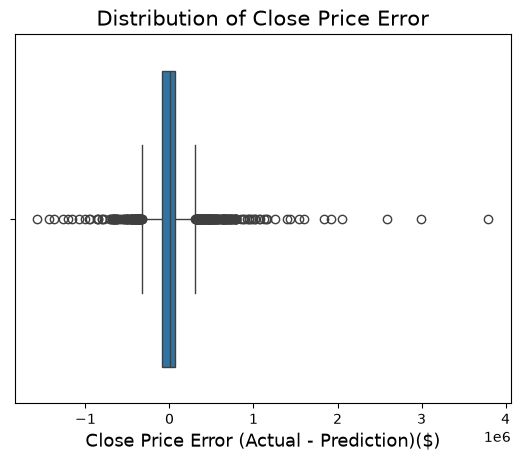

In [28]:
sns.boxplot(x = df_la["error"])
plt.xlabel("Close Price Error (Actual - Prediction)($)", fontsize = 13)
plt.title("Distribution of Close Price Error", fontsize = 15)
plt.show()

The Los Angeles of close price error distribution shows:

- The close price error distribution if right skewed and minor large underprediction error pulling average upward.

- The median of close price error is $\$1,807$, with maximum error is $\$3,794,845$ and minimum is $\$1,571,931$.

Let's split the actual close price range in Los Angeles.

In [29]:
# function for spliting price range for los angeles
def house_value(price):
    if price <= 750000:
        return "<750k"
    
    elif price > 750000 and price <= 1000000:
        return "750k-1M"

    elif price > 1000000 and price <= 1500000:
        return "1M-1.5M"

    else:
        return "1.5M+"


df_la["price_range"] = df_la["actual_price"].apply(house_value)

df_la["price_range"].value_counts()

price_range
750k-1M    706
<750k      606
1M-1.5M    577
1.5M+      470
Name: count, dtype: int64

We have splited pretty even distribution of property values. Let's group the properties with price value ranges measuring errors.

In [30]:
df_group_la_price = (
    df_la
    .groupby("price_range")
    .agg(
        N = ("actual_price", "size"),
        MAE = ("abs_error", "mean"),
        MAPE = ("APE", "mean"),
        MeanError = ("error", "mean"),
        MedianError = ("error", "median"),
        MedianActualPrice = ("actual_price", "median")
    )
    .reset_index()

)

display(df_group_la_price.round(2))

,price_range,N,MAE,MAPE,MeanError,MedianError,MedianActualPrice
0,1.5M+,470,364106.21,15.04,156319.20,132551.25,2000000.0
1,1M-1.5M,577,131733.33,10.68,-2174.91,26570.00,1240000.0
2,750k-1M,706,79822.14,9.08,-31925.88,-10040.62,860000.0
3,<750k,606,72270.17,12.52,-42488.01,-14163.88,630000.0


The Los Angeles of sold properties shows:

- The properties sold between $\$1M$ - $\$1.5M$ mean error is almost zero that nearly balanced average signed error, and the median is more underprediction distributed that majority of properties are underpredicted. This might suggest that larger overprediction errors may be pulling the average downward.

- The properties sold under $\$1.5M$ tends to overpredicted, and the lower values tends to have more errors of over prediction.

- The luxury sold properties more than $\$1.5M+$ tends to get underpredicted of close price.

- The property sold between $\$750k$ - $\$1M$ have lowest MAPE of $9.08\%$, while luxury properties have the highest $15.04\%$ and lowest value of $less \, than \,  \$750K$ shows relatively high MAPE of $\$12.52%$. **This might suggest that there is model performance disparity that model predicts well on middle class than both ends valued properties.**

- **There are difference price groups experience different levels of relative prediction error, and this might indicate that price directional prediction bias.**

Let's check if the number of observation by property values matter on model performances. We will check how training data distributed on close price.



In [31]:
# call train data of close price distribution of property value range
y_train.apply(house_value).value_counts()

ClosePrice
<750k      15761
750k-1M     8589
1M-1.5M     7338
1.5M+       6351
Name: count, dtype: int64

This indicates that:
- Below 750K properties have the largest samples of training data but not the lowest LA test MAPE result.

- The 750K - 1M properties have the best relative accuracy in Los Angeles.

- This indicates that more training samples does not guarantee on better performance in our model prediction accuracy.

In [41]:
df_county = df_fairness[
    df_fairness["CountyOrParish2"]
    .isin(["Los Angeles", "Orange", 'Riverside', 'San Diego', 'San Bernardino'])
]

df_county_similar_price = df_county[
    (df_county["actual_price"] >= 500000)
    &
    (df_county["actual_price"] <= 1000000)
]

print("Number of properties in selected range price:", df_county_similar_price.shape[0])
print(df_county_similar_price["CountyOrParish2"].value_counts())

Number of properties in selected range price: 3697
CountyOrParish2
Riverside         1227
Los Angeles       1185
San Bernardino     630
San Diego          457
Orange             198
Name: count, dtype: int64


In [42]:
df_group_similar_price = (
    df_county_similar_price
    .groupby("CountyOrParish2")
    .agg(
        N = ("actual_price", "size"),
        MAE = ("abs_error", "mean"),
        MAPE = ("APE", "mean"),
        MeanError = ("error", "mean"),
        MedianError = ("error", "median"),
        MedianActualPrice = ("actual_price", "median")
    ).reset_index()
)

display(
    df_group_similar_price
    .round(2)
    .sort_values("MAPE", ascending = False)
)

,CountyOrParish2,N,MAE,MAPE,MeanError,MedianError,MedianActualPrice
4,San Diego,457,95887.51,12.04,-49853.16,-21175.06,825000.0
1,Orange,198,97011.97,11.28,-78387.47,-56659.81,900000.0
0,Los Angeles,1185,77907.17,10.16,-36236.12,-12327.12,790400.0
3,San Bernardino,630,54730.09,8.08,598.00,7881.94,654750.0
2,Riverside,1227,53387.75,7.70,-12651.38,-1523.06,645000.0


- The order of higher MAPE is similar, even though we restricted the price range of properties. The San Diego was the highest MAPE $12.04\%$. San Bernardino of $8.08\%$ and Riverside of $7.70\%$ was the lowest MAPE in similar price value. **This indicates that model does not achieve identical predictive accruacy across counties as geographcial disparity.**

- According to mean and median error in fixed value range $\$500K$ - $\$1M$, San Bernardino both negative mean and median errors tends to  under predict the close price. On the other side, other counties tends to over predict the close price. **This might indicate that there is directional bias differences depends on geographical properties.**

# Summary

## 1. Model Explainability

- **SHAP analysis demonstrated consistency with original XGBoost predictions.** The mean reconstruction error was only $\$0.49$ with maximum error of $\$10.50$ across test observations. This indicates that SHAP feature contributions accurately reconstruct the model's predictions.

- Geographic and structural characteristics were the most influential predictors of residential ClosePrice. Latitude, Longitude, and LivingArea ranked as the top three features, each with a mean absolute SHAP value of approximately $\$165,000–\$171,000$. BathroomsTotalInteger and SalesTaxRate were the next most influential features. 

    - The Beeswarm analysis indicated that lower latitude values and larger living areas generally contributed positively to predicted ClosePrice, while longitude showed a more complex relationship.

-  Pearson and Spearman correlation analyses identified overlapping information among important predictors. Latitude and Longitude showed a strong negative Pearson correlation (r = −0.917), while LivingArea and BathroomsTotalInteger were strongly positively correlated (r = 0.818). These relationships suggest that SHAP may distribute predictive contributions across related features. **Therefore, individual SHAP values should be interpreted as model attributions rather than independent causal effects on housing prices.**

- The Waterfall plots demonstrated how individual property characteristics contributed to predictions relative to the SHAP baseline of approximately $\$1,041,591$. For Property #7219, the model predicted $\$5,620,307$ compared with an actual ClosePrice of $\$6,353,250$. The strongest positive contributions came from LivingArea, Latitude, Longitude, Orange County membership, and BathroomsTotalInteger, **this might indicates that property spacial and geographical information highly impact on model prediction.** In contrast, Property #6679 was predicted at $\$237,840$ compared with its actual ClosePrice of $\$350,000$, with geographic and structural characteristics contributing negatively to the prediction. These examples illustrate how the model uses property-specific information to produce different price estimates. 


## 2. Model Fairness 

- Due to highly influenced on location features in our model, we used county level analysis revealed differences in prediction accuracy across California housing markets in test dataset. The grouped Others category showed the highest MAPE at 24.51%, followed by San Luis Obispo (14.53%) and Alameda (14.15%). In contrast, Riverside (10.06%) and San Bernardino (10.05%) showed the lowest MAPE among the reported groups. **These findings indicate that overall predictive performance has disparity across geographic segments.**

- Los Angeles price-range performance:

    - Further analysis of $2,359$ Los Angeles properties revealed differences in model performance across actual ClosePrice ranges. Properties sold between $750K and $1M achieved the lowest MAPE of $9.08\%$, while properties below $750K had a MAPE of $12.52\%$. Properties above $1.5M experienced the highest MAPE of $15.04%$ and a positive MeanError of approximately $156,319, indicating average underprediction. In contrast, properties below $750K showed a negative MeanError of approximately −$42,488, indicating average overprediction. These results suggest that the model performs more accurately in the middle price range than at the lower and higher ends of the Los Angeles market.

    - Training sample distribution in Los Angeles:
        
        - Properties below $750K represented the largest training price group, with 15,761 observations, but they did not achieve the lowest Los Angeles test MAPE. The $750K–$1M group had the best relative prediction accuracy. **This suggests that having more training observations within a price category does not necessarily guarantee lower prediction errors**, although other factors may explain the performance differences.

- Comparable-price geographic analysis:

    - The additional across county comparison was designed to examine whether geographic performance differences matters when properties are restricted to a similar actual ClosePrice range. The highest valued properties tends to have high MAPE, however, lowest valued counties tend to have low MAPE. Additionally, only the San Bernardino faced positive mean and median errors, but other counties presented negative direction. **This suggests that geographical differences in prediction accuracy and directional errors disparity.**



## 2. Limitation

- Several influential predictors contain overlapping information, especially Latitude and Longitude, as well as LivingArea and BathroomsTotalInteger. Although TreeSHAP accurately reconstructs model predictions, its individual feature contributions depend on the trained model and explainer assumptions. Consequently, the results cannot establish independent causal relationships between property characteristics and sale prices.

- Some geographic groups contain substantially fewer observations than others. For example, the Others group contains only 110 properties and combines geographically diverse housing markets. Its relatively high MAPE may reflect limited representation and heterogeneity rather than a consistent regional model deficiency. Small groups can also produce less stable error estimates.

- The analysis evaluates prediction consistency across counties and housing price segments rather than protected demographic groups. County-level disparities alone do not establish discrimination because regional differences may reflect property characteristics and market conditions. Additional demographic or other features of contexts would be necessary to investigate whether geographic prediction errors fair enough on model performance.


## 3. Future Work

-  Extend the analysis using County × ClosePrice Range comparisons across multiple price intervals. Include counties with sufficient observations, particularly Los Angeles and Orange County, to investigate whether geographic prediction disparities persist among similarly priced residential properties.

- Compare prediction errors across combinations of county, property age, living area, and other relevant structural characteristics. This could help determine whether certain housing segments experience consistently higher errors even within the same geographic region and price range.

- Investigate CPI and longitude/latitude of relationship with close price, due to the results from SHAP analysis. 

- If suitable and ethically appropriate demographic or neighborhood-level information becomes available, investigate whether geographic disparities are associated with broader socioeconomic inequalities. Such analysis should distinguish geographic association from evidence of demographic discrimination.


# Deploy Model

We will use **Joblib** library that used to save and reload trained machine learning models or pipelines saving to a file as '**model.pkl**'. 

Additionally, we will import **Streamlit** library to build the interactive web application. It is used to create the input fields and other application features that users can interact with in deployed model. 

**This process is the purpose to show the process of producing the deployed model into application. The other users are unecessary to follow this process, and here is the website where users can use the model directly without process.**

Deployed Model: https://californiarealestatedatascience-wct97ezpa4x4gpzaxcrale.streamlit.app/ 

Download the Streamlit in terminal "**pip install streamlit**".

In [34]:
import joblib
import streamlit as st

# Save trained XGBoost model
joblib.dump(pipeline_model, 'model.pkl')
print("XGBoost model saved as 'model.pkl'")

XGBoost model saved as 'model.pkl'


We will make the file of Python prompt called '**app.py**' setting the application website of deploying the model. This prompt will be use in the Streamlit of community cloud website connecting to Github so that it operates application.

- Streamlit website: https://streamlit.io/cloud

- Github: https://github.com/junkuna/California_Real_Estate_Data_Science/tree/main 

This process is the purpose to show the process of producing the deployed model into application. The other users are unecessary to follow this process, 

In [35]:
%%writefile app.py

# Load trained preprocessing + XGBoost pipeline
model = joblib.load("model.pkl")

# Get exact categories used during training
encoder = (
    model
    .named_steps["preprocessor"]
    .named_transformers_["categorical"]
)

categorical_columns = [
    "CountyOrParish2",
    "FlooringType2",
    "AttachedGarageYN",
    "FireplaceYN",
    "NewConstructionYN",
    "PoolPrivateYN",
    "ViewYN"
]

category_options = dict(
    zip(categorical_columns, encoder.categories_)
)

# set page configure
st.set_page_config(
    page_title="California Home Price Predictor",
    page_icon="🏠"
)

# set title
st.title("🏠 California Home Price Predictor")

# set information below title
st.write(
    "Enter the property and market information below "
    "to estimate the expected sale price."
)


# property information
st.subheader("Property Information")

living_area = st.number_input(
    "Living Area (sq ft)",
    min_value=0.0,
    value=1800.0
)

lot_size = st.number_input(
    "Lot Size (sq ft)",
    min_value=0.0,
    value=7000.0
)

age = st.number_input(
    "Property Age",
    min_value=0,
    value=30
)

bedrooms = st.number_input(
    "Bedrooms",
    min_value=0,
    value=3
)

bathrooms = st.number_input(
    "Bathrooms",
    min_value=0,
    value=2
)

stories = st.number_input(
    "Stories",
    min_value=0,
    value=1
)

garage_spaces = st.number_input(
    "Garage Spaces",
    min_value=0,
    value=2
)

parking_total = st.number_input(
    "Total Parking Spaces",
    min_value=0,
    value=2
)


# property location settting
st.subheader("Location")

latitude = st.number_input(
    "Latitude",
    value=34.0522,
    format="%.6f"
)

longitude = st.number_input(
    "Longitude",
    value=-118.2437,
    format="%.6f"
)

county = st.selectbox(
    "County",
    category_options["CountyOrParish2"]
)

school_count = st.number_input(
    "Public Schools Within 2 Miles",
    min_value=0,
    value=10
)


# additional property information setting
st.subheader("Additional Features")

flooring = st.selectbox(
    "Flooring Type",
    category_options["FlooringType2"]
)

attached_garage = st.selectbox(
    "Attached Garage",
    category_options["AttachedGarageYN"],
    format_func=lambda x: "Yes" if x == 1 else "No"
)

fireplace = st.selectbox(
    "Fireplace",
    category_options["FireplaceYN"],
    format_func=lambda x: "Yes" if x == 1 else "No"
)

new_construction = st.selectbox(
    "New Construction",
    category_options["NewConstructionYN"],
    format_func=lambda x: "Yes" if x == 1 else "No"
)

private_pool = st.selectbox(
    "Private Pool",
    category_options["PoolPrivateYN"],
    format_func=lambda x: "Yes" if x == 1 else "No"
)

view = st.selectbox(
    "View",
    category_options["ViewYN"],
    format_func=lambda x: "Yes" if x == 1 else "No"
)


# setting real estate market condition settting
st.subheader("Market Conditions")

cpi = st.number_input(
    "CPI",
    value=320.0
)

fed_rate = st.number_input(
    "Federal Interest Rate",
    value=4.5
)

mortgage_rate = st.number_input(
    "30-Year Mortgage Rate",
    value=6.5
)

unemployment_rate = st.number_input(
    "Unemployment Rate",
    value=5.0
)

sales_tax_rate = st.number_input(
    "Sales Tax Rate",
    value=7.25
)

lot_density = st.number_input(
    "Lot Density",
    value=0.25
)


# model predict execution
if st.button("Predict Sale Price"):

    input_data = pd.DataFrame(
        [{
            "Age": age,
            "CPI": cpi,
            "FedInterestRate": fed_rate,
            "Latitude": latitude,
            "LivingArea": living_area,
            "Longitude": longitude,
            "LotDensity": lot_density,
            "LotSizeSquareFeet": lot_size,
            "MortgageRate30Fixed": mortgage_rate,
            "SalesTaxRate": sales_tax_rate,
            "UnemploymentRate": unemployment_rate,

            "BathroomsTotalInteger": bathrooms,
            "BedroomsTotal": bedrooms,
            "Stories": stories,
            "GarageSpaces": garage_spaces,
            "ParkingTotal": parking_total,
            "SchoolCount2Miles": school_count,

            "CountyOrParish2": county,
            "FlooringType2": flooring,
            "AttachedGarageYN": attached_garage,
            "FireplaceYN": fireplace,
            "NewConstructionYN": new_construction,
            "PoolPrivateYN": private_pool,
            "ViewYN": view
        }]
    )

    prediction = model.predict(input_data)[0]

    st.success(
        f"Estimated Sale Price: ${prediction:,.0f}"
    )

Overwriting app.py


Let's make requirement text prompt for the Streamlit application aligning which Python packages it must be installed to run the model. 

In [36]:
%%writefile requirements.txt

streamlit
pandas
numpy
scikit-learn
xgboost
joblib

Overwriting requirements.txt
